# Before you begin


1.   Use the [Cloud Resource Manager](https://console.cloud.google.com/cloud-resource-manager) to Create a Cloud Platform project if you do not already have one.
2.   [Enable billing](https://support.google.com/cloud/answer/6293499#enable-billing) for the project.
3.   [Enable BigQuery](https://console.cloud.google.com/flows/enableapi?apiid=bigquery) APIs for the project.


### Provide your Google Cloud credentials to the runtime

In [1]:
from google.colab import auth
auth.authenticate_user()
print('Authenticated')

Authenticated


## Optional: Enable data table display

Colab includes the ``google.colab.data_table`` package that can be used to display large pandas dataframes as an interactive data table.
It can be enabled with:

In [2]:
%load_ext google.colab.data_table

If you would prefer to return to the classic Pandas dataframe display, you can disable this by running:
```python
%unload_ext google.colab.data_table
```

Declare the Cloud project ID which will be used throughout this notebook

In [3]:
project_id = 'cmpelkk'

In [4]:
!gcloud config list

[component_manager]
disable_update_check = True
[compute]
gce_metadata_read_timeout_sec = 0
[core]
account = kaikai.liu@sjsu.edu

Your active configuration is: [default]


In [5]:
#!gcloud config set compute/region us-central1
#!gcloud config set compute/zone us-central1-a
!gcloud config list project

[core]
project (unset)

Your active configuration is: [default]


In [6]:
!gcloud config set project 'cmpelkk'

Updated property [core/project].


In [7]:
!gcloud config list project

[core]
project = cmpelkk

Your active configuration is: [default]


# Check my BigQuery Data

In [8]:
from google.cloud import bigquery

# https://cloud.google.com/resource-manager/docs/creating-managing-projects
project_id = 'cmpelkk'
client = bigquery.Client(project=project_id)

#Print your current data
for dataset in client.list_datasets():
  print(dataset.dataset_id)

MLtest1
census
covid_demo
dataproctest
heartRateData
iottest
weatherData


# Natality dataset
Describes all United States births registered in the 50 States, the District of Columbia, and New York City from 1969 to 2008.
Table size
21.94 GB
Long-term storage size
21.94 GB
Number of rows
137,826,763
Check schema: https://console.cloud.google.com/bigquery?p=bigquery-public-data&d=samples&t=natality&page=table&_ga=2.9494645.1369982042.1629396963-1008762737.1614618655&project=cmpelkk&ws=!1m5!1m4!4m3!1sbigquery-public-data!2ssamples!3snatality

In [17]:
query1 = """SELECT
  *
FROM
  `bigquery-public-data.samples.natality`
WHERE
  year >= 2006
  AND year <= 2008
ORDER BY
  year,
  is_male
LIMIT 200
        """
dfquery = client.query(query1)

In [18]:
df_natality=dfquery.to_dataframe()
df_natality.head(200)

,source_year,year,month,day,wday,state,is_male,child_race,weight_pounds,plurality,apgar_1min,apgar_5min,mother_residence_state,mother_race,mother_age,gestation_weeks,lmp,mother_married,mother_birth_state,cigarette_use,cigarettes_per_day,alcohol_use,drinks_per_week,weight_gain_pounds,born_alive_alive,born_alive_dead,born_dead,ever_born,father_race,father_age,record_weight
0,2006,2006,6,None,4,None,False,None,8.062305,1,None,10.0,None,1.0,34,38.0,09122005,True,None,False,NaN,False,NaN,14.0,None,None,None,8.0,1.0,38,1
1,2006,2006,1,None,3,None,False,None,6.657960,1,None,NaN,None,NaN,39,40.0,04162005,False,None,None,NaN,None,NaN,99.0,None,None,None,8.0,NaN,25,1
2,2006,2006,7,None,3,None,False,None,7.625790,1,None,9.0,None,1.0,32,37.0,10222005,True,None,False,NaN,False,NaN,38.0,None,None,None,8.0,1.0,26,1
3,2006,2006,5,None,4,None,False,None,5.562263,1,None,9.0,None,NaN,24,39.0,08092005,False,None,None,NaN,None,NaN,30.0,None,None,None,8.0,NaN,99,1
4,2006,2006,4,None,3,None,False,None,6.968812,1,None,NaN,None,NaN,36,39.0,07082005,True,None,None,NaN,None,NaN,99.0,None,None,None,8.0,NaN,50,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
195,2006,2006,1,None,5,None,False,None,9.248392,1,None,9.0,None,NaN,34,40.0,04152005,True,None,None,NaN,None,NaN,29.0,None,None,None,8.0,NaN,41,1
196,2006,2006,11,None,6,None,False,None,8.811877,1,None,10.0,None,1.0,45,41.0,02102006,True,None,False,NaN,False,NaN,25.0,None,None,None,8.0,1.0,46,1
197,2006,2006,12,None,2,None,False,None,8.750147,1,None,NaN,None,NaN,40,40.0,03112006,True,None,None,NaN,None,NaN,99.0,None,None,None,8.0,NaN,40,1
198,2006,2006,1,None,3,None,False,None,7.625790,1,None,9.0,None,NaN,36,40.0,04012005,True,None,None,NaN,None,NaN,29.0,None,None,None,8.0,NaN,38,1


In [20]:
#The following cell executes a query of the BigQuery natality public dataset and returns the total births by year.
query2 = """
SELECT
    source_year AS year,
    COUNT(is_male) AS birth_count
FROM `bigquery-public-data.samples.natality`
GROUP BY year
ORDER BY year DESC
LIMIT 200
        """
dfquery = client.query(query2)

In [21]:
df_birthcount=dfquery.to_dataframe()
df_birthcount.head()

,year,birth_count
0,2008,4255156
1,2007,4324008
2,2006,4273225
3,2005,4145619
4,2004,4118907


The next cell uses the pandas DataFrame.plot method to visualize the query results as a bar chart. See the pandas documentation to learn more about data visualization with pandas.

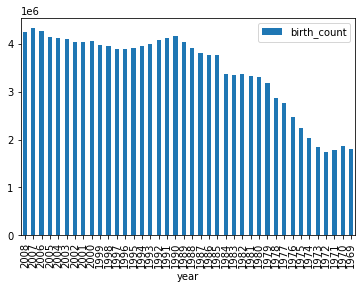

In [22]:
df_birthcount.plot(kind='bar', x='year', y='birth_count')

Run the following query to retrieve the number of births by weekday. Because the wday (weekday) field allows null values, the query excludes records where wday is null.

In [23]:
query3 = """
SELECT
    wday,
    SUM(CASE WHEN is_male THEN 1 ELSE 0 END) AS male_births,
    SUM(CASE WHEN is_male THEN 0 ELSE 1 END) AS female_births
FROM `bigquery-public-data.samples.natality`
WHERE wday IS NOT NULL
GROUP BY wday
ORDER BY wday ASC
        """
dfquery = client.query(query3)

In [24]:
df_wday=dfquery.to_dataframe()
df_wday.head()

,wday,male_births,female_births
0,1,4293575,4093357
1,2,6095840,5831111
2,3,6727217,6412155
3,4,6618729,6307782
4,5,6583015,6284434


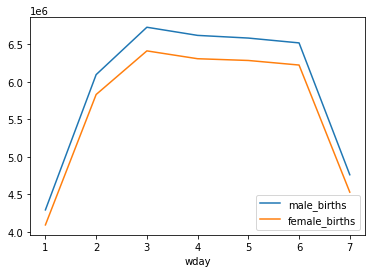

In [25]:
df_wday.plot(x='wday');

In [26]:
#query to retrieve the count of births by the number of gestation weeks
sql = """
SELECT
    gestation_weeks,
    COUNT(1) AS count
FROM
    `bigquery-public-data.samples.natality`
WHERE
    NOT IS_NAN(gestation_weeks) AND gestation_weeks <> 99
GROUP BY
    gestation_weeks
ORDER BY
    gestation_weeks
"""
df_week = client.query(sql).to_dataframe()

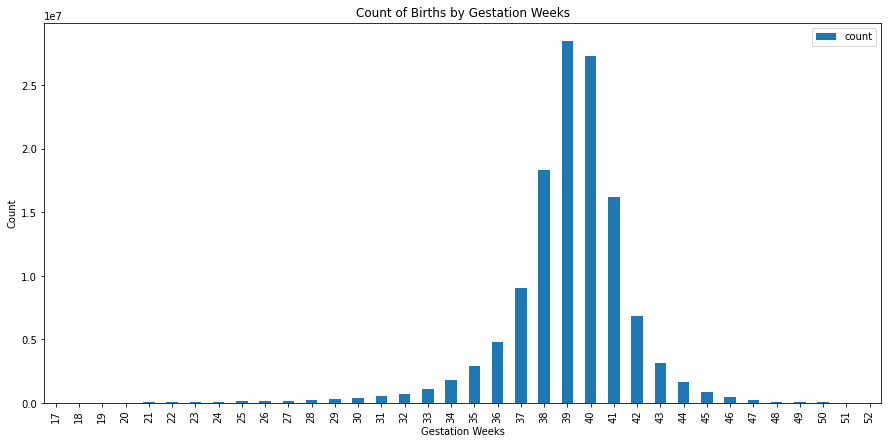

In [27]:
ax = df_week.plot(kind='bar', x='gestation_weeks', y='count', figsize=(15,7))
ax.set_title('Count of Births by Gestation Weeks')
ax.set_xlabel('Gestation Weeks')
ax.set_ylabel('Count');

How many boys and girls were born between the years 2000 and 2002?

In [29]:
sql = """SELECT
  year,
  is_male,
  COUNT(1) as count
FROM
  `bigquery-public-data.samples.natality`
WHERE
  year >= 2000
  AND year <= 2002
GROUP BY
  year, is_male
ORDER BY
  year,
  is_male;
        """
df_boygirl = client.query(sql).to_dataframe()
df_boygirl.head(10)

,year,is_male,count
0,2000,False,1984255
1,2000,True,2079568
2,2001,False,1970770
3,2001,True,2060761
4,2002,False,1966519
5,2002,True,2060857


In [46]:
sql = """SELECT
  year,
  /* Finds average and standard deviation */
  AVG(weight_pounds) baby_weight,
  STDDEV(weight_pounds) baby_weight_stdev,
  AVG(mother_age) mother_age
FROM
  `bigquery-public-data.samples.natality`
WHERE
  year>2000 AND state='CA'
/* Group the result values by those */
/* who smoked and those who didn't.  */
GROUP BY
  year;
        """
df_cigarette = client.query(sql).to_dataframe()
df_cigarette.head(10)

,year,baby_weight,baby_weight_stdev,mother_age
0,2003,7.345123,1.280523,28.053679
1,2004,7.322344,1.277292,28.083823
2,2002,7.371910,1.284255,27.930534
3,2001,7.382873,1.283766,27.818085


In [71]:
sql = """SELECT
  year, state, is_male, weight_pounds, mother_age, gestation_weeks, mother_married, cigarette_use, alcohol_use
FROM
  `bigquery-public-data.samples.natality`
WHERE
  year >= 2000 AND cigarette_use IS NOT NULL AND alcohol_use IS NOT NULL
ORDER BY
  year
LIMIT 500
        """
df_part = client.query(sql).to_dataframe()

In [72]:
df_part

,year,state,is_male,weight_pounds,mother_age,gestation_weeks,mother_married,cigarette_use,alcohol_use
0,2003,MO,False,7.687519,19,40.0,True,False,False
1,2003,LA,False,6.874013,38,41.0,False,False,False
2,2003,TX,True,6.375769,27,NaN,True,False,False
3,2003,UT,True,7.193684,33,40.0,False,True,True
4,2003,MI,True,4.561364,38,36.0,True,True,True
...,...,...,...,...,...,...,...,...,...
495,2003,OR,True,8.811877,41,40.0,False,False,False
496,2003,NY,True,8.249698,40,39.0,True,False,False
497,2003,MO,False,6.375769,42,37.0,True,False,False
498,2003,WI,True,8.950768,32,37.0,True,False,False


In [73]:
df_part.shape

(500, 9)

In [74]:
df_part['cigarette_use'].value_counts()

False    448
True      52
Name: cigarette_use, dtype: int64

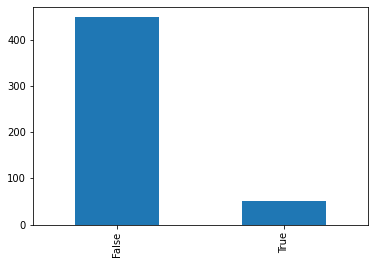

In [78]:
df_part['cigarette_use'].value_counts().plot(kind = 'bar')

Note: putting a semicolon after a plot call hides all of the unnecessary text that comes after it (the <matplotlib.axes_....>).

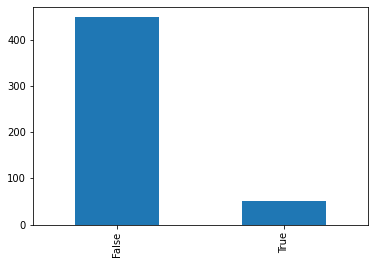

In [77]:
df_part['alcohol_use'].value_counts().plot(kind = 'bar');

In [80]:
import seaborn as sns

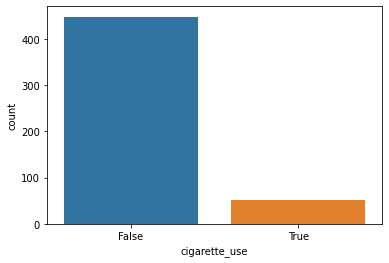

In [81]:
sns.countplot(x=df_part['cigarette_use']);

In [82]:
bweights = df_part["weight_pounds"]

In [84]:
bweights

0      7.687519
1      6.874013
2      6.375769
3      7.193684
4      4.561364
         ...   
495    8.811877
496    8.249698
497    6.375769
498    8.950768
499    6.834330
Name: weight_pounds, Length: 500, dtype: float64

In [86]:
import matplotlib.pyplot as plt

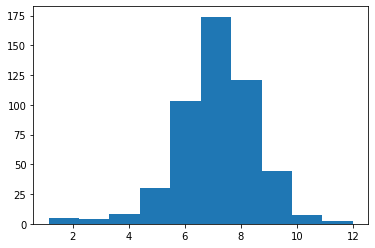

In [87]:
# By default, you get some arbitrary bins. We often like to pick our own.
plt.hist(bweights);

In [88]:
min(bweights), max(bweights)

(1.14199451716, 11.99976092066)

In [98]:
bw_bins = range(0, 15, 1)

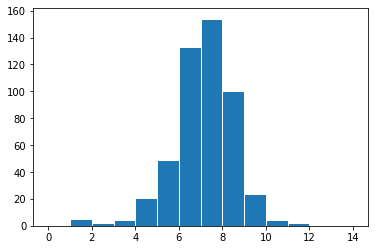

In [99]:
plt.hist(bweights, bins=bw_bins, ec='w');

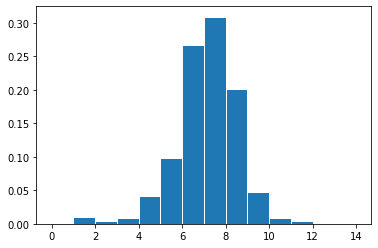

In [100]:
#if we want to see a distribution we can use the density keyword:
plt.hist(bweights, density=True, bins=bw_bins, ec='w');

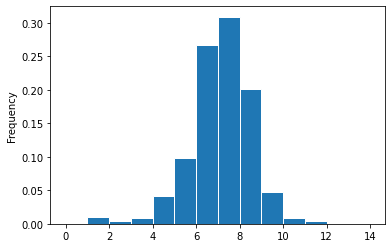

In [101]:
# alternative way of getting this plot
bweights.plot(kind = 'hist', density=True, bins=bw_bins, ec='w');

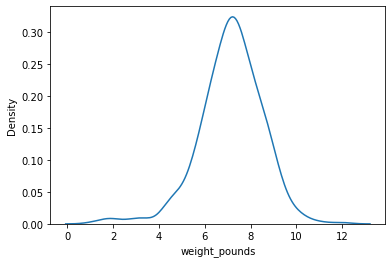

In [102]:
sns.kdeplot(bweights);#Density Curves

Seaborn has several related functions for plotting distributions: kdeplot, histplot, rugplot and displot. The latter is more generic but uses the others under the hood:

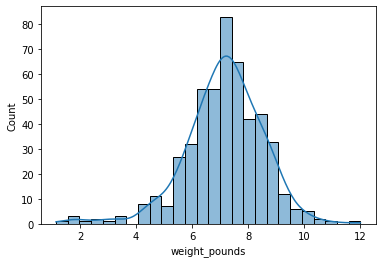

In [103]:
sns.histplot(bweights, kde=True);

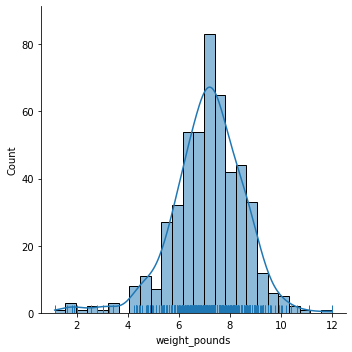

In [104]:
sns.displot(bweights, kde=True, rug=True);

A rug plot is a plot of data for a single quantitative variable, displayed as marks along an axis. It is used to visualise the distribution of the data. As such it is analogous to a histogram with zero-width bins, or a one-dimensional scatter plot.

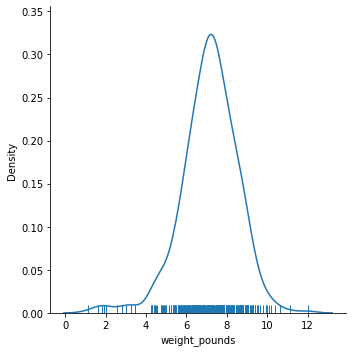

In [105]:
#displot is quite flexible, so instead of a histogram we can ask it, for example, to show the density curve and rugplot only:
sns.displot(bweights, kind='kde', rug=True);

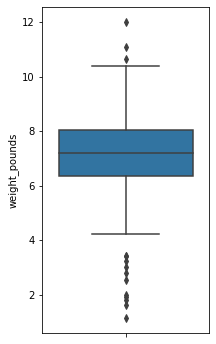

In [106]:
#box plot
plt.figure(figsize = (3, 6))
sns.boxplot(y=bweights);

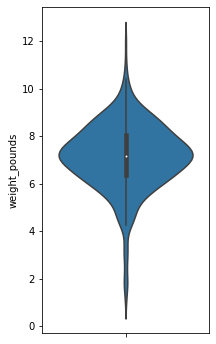

In [107]:
plt.figure(figsize = (3, 6))
sns.violinplot(y=bweights);

In [108]:
#df_part["weight_pounds"]
sm_bweights = df_part[df_part['cigarette_use'] == True]["weight_pounds"]
nsm_bweights = df_part[df_part['cigarette_use'] == False]["weight_pounds"]

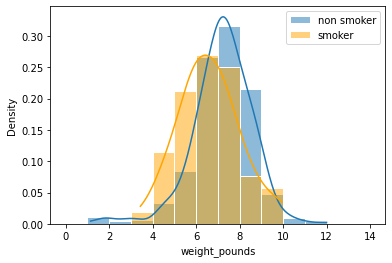

In [109]:
sns.histplot(nsm_bweights, bins=bw_bins, kde=True, stat='density', label='non smoker', ec='w');
sns.histplot(sm_bweights, bins=bw_bins, kde=True, stat='density', label='smoker', color='orange', ec='w');
plt.legend();

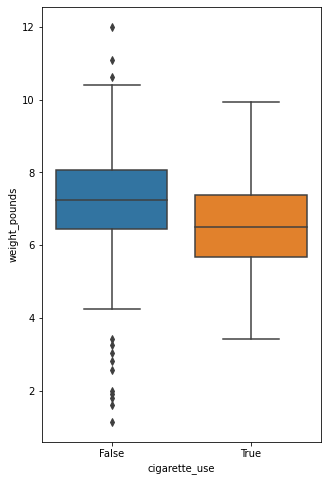

In [111]:
plt.figure(figsize=(5, 8))
sns.boxplot(data=df_part, x = 'cigarette_use', y = 'weight_pounds');

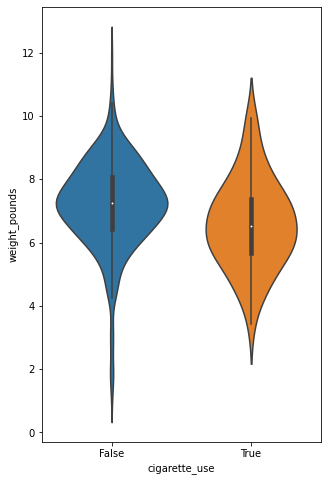

In [112]:
plt.figure(figsize=(5, 8))
sns.violinplot(data=df_part, x = 'cigarette_use', y = 'weight_pounds');

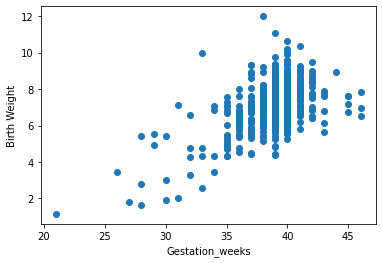

In [114]:
plt.scatter(df_part['gestation_weeks'], df_part['weight_pounds']);
plt.xlabel('Gestation_weeks')
plt.ylabel('Birth Weight');

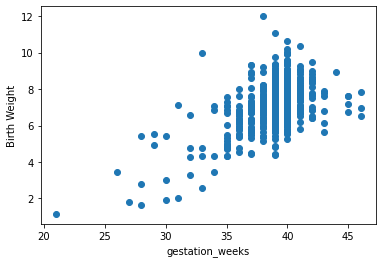

In [115]:
plt.scatter(data=df_part, x='gestation_weeks', y='weight_pounds');
plt.xlabel('gestation_weeks')
plt.ylabel('Birth Weight');

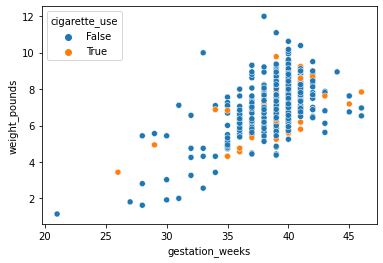

In [116]:
sns.scatterplot(data = df_part, x = 'gestation_weeks', y = 'weight_pounds', hue = 'cigarette_use');

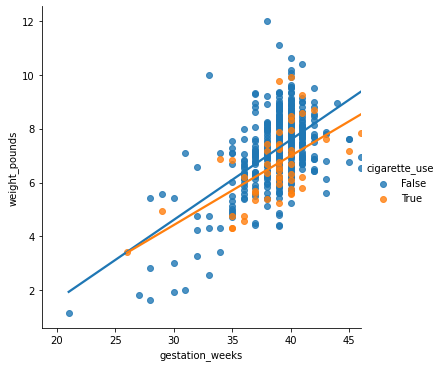

In [117]:
sns.lmplot(data = df_part, x = 'gestation_weeks', y = 'weight_pounds', ci=False, hue='cigarette_use');

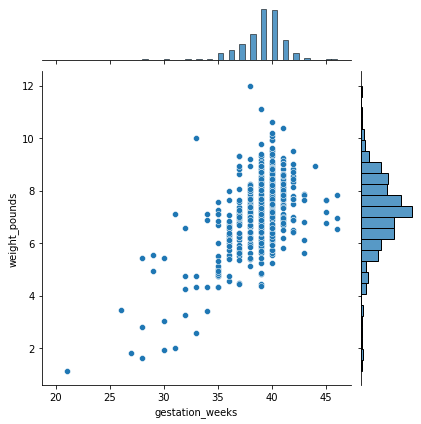

In [118]:
sns.jointplot(data = df_part, x = 'gestation_weeks', y = 'weight_pounds');

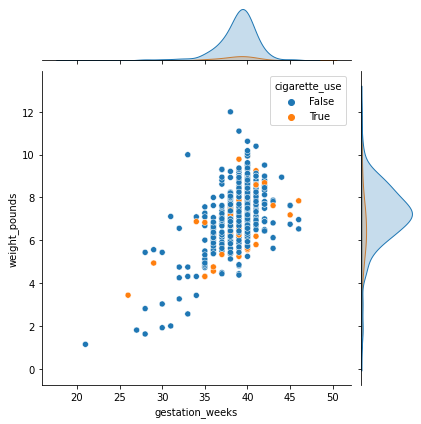

In [120]:
sns.jointplot(data = df_part, x = 'gestation_weeks', y = 'weight_pounds', hue='cigarette_use');

Hex plots and contour plots

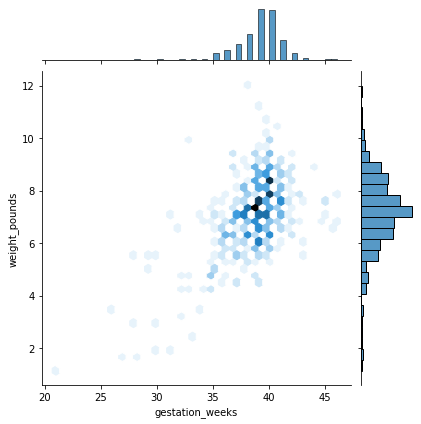

In [121]:
sns.jointplot(data = df_part, x = 'gestation_weeks', y = 'weight_pounds', kind='hex');

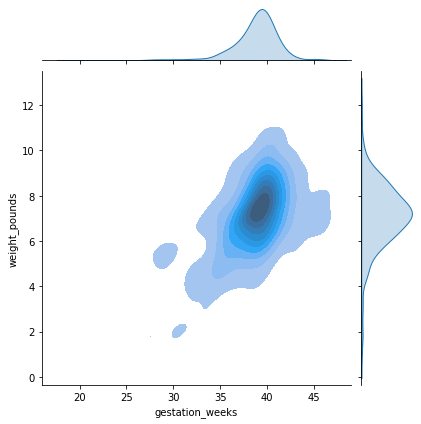

In [122]:
sns.jointplot(data = df_part, x = 'gestation_weeks', y = 'weight_pounds', kind='kde', fill=True);

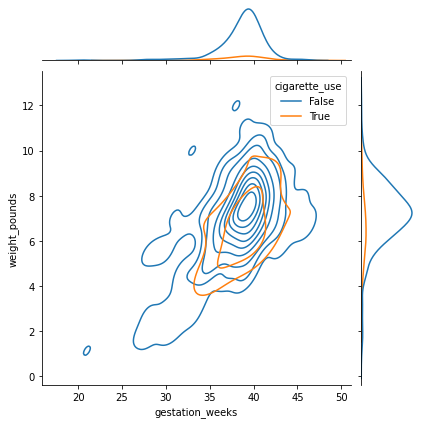

In [124]:
sns.jointplot(data = df_part, x = 'gestation_weeks', y = 'weight_pounds', kind='kde', hue='cigarette_use');

# Weather

Use BigQuery via magics: The google.cloud.bigquery library also includes a magic command which runs a query and either displays the result or saves it to a variable as a DataFrame.

In [126]:
%%bigquery weather_JFK --project cmpelkk
SELECT
  *
FROM
    `bigquery-public-data.noaa_gsod.gsod2019`
WHERE
  stn="744860"   -- JFK

In [127]:
weather_JFK

,stn,wban,year,mo,da,temp,count_temp,dewp,count_dewp,slp,count_slp,stp,count_stp,visib,count_visib,wdsp,count_wdsp,mxpsd,gust,max,flag_max,min,flag_min,prcp,flag_prcp,sndp,fog,rain_drizzle,snow_ice_pellets,hail,thunder,tornado_funnel_cloud
0,744860,94789,2019,01,05,44.5,24,43.5,24,1004.6,14,2.0,24,5.0,24,9.1,24,20.0,28.0,46.4,*,42.8,*,0.24,G,999.9,0,1,0,0,0,0
1,744860,94789,2019,07,18,77.5,24,75.2,24,1012.2,15,11.6,24,9.1,24,6.6,24,25.1,36.9,90.0,None,73.0,None,0.87,G,999.9,0,1,0,0,1,0
2,744860,94789,2019,10,27,60.3,24,56.5,24,1019.9,15,14.4,23,7.7,24,12.4,24,22.9,32.1,69.1,None,50.0,None,0.04,G,999.9,0,1,0,0,0,0
3,744860,94789,2019,02,18,36.2,24,32.2,24,1014.6,15,12.2,24,7.2,24,8.7,24,22.9,35.0,43.0,None,25.0,None,0.11,G,999.9,0,1,0,0,0,0
4,744860,94789,2019,12,14,53.1,24,53.1,24,1007.4,7,0.0,24,1.9,24,9.4,24,20.0,24.1,55.4,*,50.0,*,2.72,G,999.9,1,1,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
360,744860,94789,2019,07,03,79.0,24,71.5,24,1010.1,24,9.3,24,9.9,24,4.8,24,9.9,999.9,89.1,None,66.9,None,0.09,G,999.9,0,1,0,0,0,0
361,744860,94789,2019,07,08,72.3,24,63.2,24,1015.0,24,14.2,24,10.0,24,4.8,24,8.0,999.9,84.9,None,70.0,None,0.00,G,999.9,0,1,0,0,0,0
362,744860,94789,2019,11,16,39.9,24,15.8,24,1027.6,24,26.8,24,10.0,24,13.4,24,21.0,29.9,51.1,None,34.0,None,0.00,G,999.9,0,0,0,0,0,0
363,744860,94789,2019,05,22,64.6,24,38.4,24,1021.6,24,20.8,24,10.0,24,11.0,24,21.0,27.0,73.0,None,55.0,None,0.00,G,999.9,0,0,0,0,0,0


In [128]:
%%bigquery weather_JFK_filtered --project cmpelkk
SELECT
  -- Create a timestamp from the date components.
  timestamp(concat(year,"-",mo,"-",da)) as timestamp,
  -- Replace numerical null values with actual nulls
  AVG(IF (temp=9999.9, null, temp)) AS temperature,
  AVG(IF (visib=999.9, null, visib)) AS visibility,
  AVG(IF (wdsp="999.9", null, CAST(wdsp AS Float64))) AS wind_speed,
  AVG(IF (gust=999.9, null, gust)) AS wind_gust,
  AVG(IF (prcp=99.99, null, prcp)) AS precipitation,
  AVG(IF (sndp=999.9, null, sndp)) AS snow_depth
FROM
  `bigquery-public-data.noaa_gsod.gsod20*`
WHERE
  CAST(YEAR AS INT64) > 2018
  AND stn="744860"    -- JFK
GROUP BY timestamp

In [129]:
weather_JFK_filtered

,timestamp,temperature,visibility,wind_speed,wind_gust,precipitation,snow_depth
0,2021-04-08 00:00:00+00:00,53.2,10.0,5.6,NaN,0.00,NaN
1,2021-02-24 00:00:00+00:00,41.4,10.0,12.3,33.0,0.00,1.2
2,2021-08-05 00:00:00+00:00,72.0,10.0,8.2,NaN,0.00,NaN
3,2021-06-27 00:00:00+00:00,74.6,9.9,13.3,27.0,0.00,NaN
4,2021-04-07 00:00:00+00:00,56.6,10.0,6.0,NaN,0.00,NaN
...,...,...,...,...,...,...,...
954,2020-03-25 00:00:00+00:00,43.9,10.0,12.0,26.0,0.00,NaN
955,2020-08-18 00:00:00+00:00,73.1,10.0,8.6,24.1,0.13,NaN
956,2020-07-01 00:00:00+00:00,71.5,9.9,4.7,NaN,0.00,NaN
957,2020-03-23 00:00:00+00:00,38.6,7.3,14.9,33.0,0.00,NaN


724940 23234 SAN FRANCISCO INTERNATIONAL A ref: https://www1.ncdc.noaa.gov/pub/data/noaa/isd-history.txt

In [130]:
#@title Get Daily Temperature Data for SFO Station (2019)
%%bigquery SFO_daily_2019 --project cmpelkk

SELECT
  # Station information
  daily_weather.stn AS usaf,
  
  # Convert year/month/day info into date
  DATE(
    CAST(daily_weather.year AS INT64),
    CAST(daily_weather.mo AS INT64),
    CAST(daily_weather.da AS INT64)
    ) AS date,
  
  daily_weather.temp AS avg_temp,
  daily_weather.count_temp AS n_for_avg_temp,
  
  daily_weather.max AS max_temp,
  daily_weather.flag_max AS max_temp_flag,
  
  daily_weather.min AS min_temp,
  daily_weather.flag_min AS min_temp_flag

FROM
  `bigquery-public-data.noaa_gsod.gsod2019` daily_weather

WHERE 
  # Filter to only chosen station
  daily_weather.stn = "724940" AND
  # Remove days w/ missing temps coded as 99999.9 (can throw off calculations)
  daily_weather.temp != 9999.9 AND
  daily_weather.max != 9999.9 AND
  daily_weather.min != 9999.9

ORDER BY
  date DESC

In [131]:
SFO_daily_2019

,usaf,date,avg_temp,n_for_avg_temp,max_temp,max_temp_flag,min_temp,min_temp_flag
0,724940,2019-12-31,50.2,24,59.0,None,41.0,None
1,724940,2019-12-30,51.8,24,59.0,None,46.9,None
2,724940,2019-12-29,53.0,24,59.0,None,39.9,None
3,724940,2019-12-28,49.1,24,59.0,None,39.0,None
4,724940,2019-12-27,49.1,24,59.0,None,39.0,None
...,...,...,...,...,...,...,...,...
360,724940,2019-01-05,53.1,24,63.0,None,39.0,None
361,724940,2019-01-04,46.8,24,63.0,None,39.0,None
362,724940,2019-01-03,46.2,24,54.0,None,37.9,None
363,724940,2019-01-02,46.3,24,55.0,None,37.9,None


In [132]:
# 10 highest avg_temp samples
SFO_daily_2019.sort_values('avg_temp', ascending=False).head(10)

,usaf,date,avg_temp,n_for_avg_temp,max_temp,max_temp_flag,min_temp,min_temp_flag
203,724940,2019-06-11,79.0,24,100.0,None,66.9,None
204,724940,2019-06-10,78.1,24,100.0,None,55.0,None
97,724940,2019-09-25,77.7,24,96.1,None,61.0,None
202,724940,2019-06-12,76.9,24,98.1,None,66.9,None
96,724940,2019-09-26,74.5,24,96.1,None,64.0,None
109,724940,2019-09-13,74.4,24,93.9,None,61.0,None
68,724940,2019-10-24,73.6,24,89.1,None,55.0,None
138,724940,2019-08-15,73.0,24,93.9,None,61.0,None
98,724940,2019-09-24,72.3,24,93.9,None,57.9,None
205,724940,2019-06-09,72.1,24,91.9,None,52.0,None


In [133]:
import pandas as pd

# Create table of temperature series to plot, with names, symbols, colors
daily_temp_plot_fields = pd.DataFrame.from_records(  
  columns = ['field_name', 'plot_label', 'marker_symbol', 'line_color', 
    'plot_mode'],
  data = [
    ('avg_temp', 'Avg', 'circle', None, 'markers'),
    ('max_temp', 'Max', 'triangle-up', None, 'markers'),
    ('min_temp', 'Min', 'triangle-down', None, 'markers')
    ]
  )

In [134]:
daily_temp_plot_fields

,field_name,plot_label,marker_symbol,line_color,plot_mode
0,avg_temp,Avg,circle,None,markers
1,max_temp,Max,triangle-up,None,markers
2,min_temp,Min,triangle-down,None,markers


In [135]:
import plotly.graph_objects as go
import plotly.io as pio

# Create function to plot single station daily temperature
def plot_single_station_daily_temp(daily_temp_data, plot_fields, station_name):
  daily_plot_data = []

  for index, row in plot_fields.iterrows():
    daily_plot_data = (daily_plot_data +
      [go.Scatter(
        x = daily_temp_data['date'],
        y = daily_temp_data[row['field_name']],
        name = row['plot_label'],
        marker = dict(
          # Constant color scale for plotting temp to use for all stations
          cmin = -22, # -22°F corresponds to -30°C (very cold, to most)
          cmax = 122, # 122°F corresponds to 50°C (very hot, to most)
          color = daily_temp_data[row['field_name']], 
          # colorscale = 'BlueReds',
          colorscale = [[0, 'rgb(0, 0, 230)'], [0.5, 'rgb(190, 190, 190)'],
            [1, 'rgb(230, 0, 0)']],
          symbol = row['marker_symbol']
          ),
        line = dict(
          color = row['line_color']
          ),
        mode = row['plot_mode']
        )]
      )

  daily_plot_layout = go.Layout(
    title = dict(
      text = (station_name + ' Daily Temperature'),
      xref = "paper", 
      x = 0.5
      ),
    yaxis = dict(title = 'Temperature (°F)')
    )

  pio.show(go.Figure(daily_plot_data, daily_plot_layout))

In [137]:
chosen_station_name="SFO"
plot_single_station_daily_temp(SFO_daily_2019,
  daily_temp_plot_fields, chosen_station_name)

## Multi-Year data for SFO

In [138]:
import numpy as np

#@title Get and Plot Multi-Year Daily Temperature Data for Chosen Station
chosen_start_year = 2005 #@param{type:"integer"}

chosen_end_year = 2019 #@param{type:"integer"}

def get_single_station_daily_temp_multiple_yrs(station_usaf, start_year, 
  end_year):
  
  single_station_daily_weather_multiyear_union_sql = ("\nUNION ALL\n".
    join([('''
      ( SELECT * FROM `bigquery-public-data.noaa_gsod.gsod{year}`
      WHERE stn = '{station_usaf}')
      ''')
    .format(year = year, station_usaf = station_usaf)
       for year in np.arange(start_year, (end_year + 1))
    ]))

  single_station_daily_multiyear_sql = '''
    WITH
    daily_weather AS
    (
      {daily_weather_table}
    )

    SELECT
      daily_weather.stn AS usaf,
      
      # Convert year/month/day info into date
      DATE(
        CAST(daily_weather.year AS INT64),
        CAST(daily_weather.mo AS INT64),
        CAST(daily_weather.da AS INT64)
        ) AS date,
      
      daily_weather.temp AS avg_temp,
      daily_weather.count_temp AS n_for_avg_temp,
      
      daily_weather.max AS max_temp,
      daily_weather.flag_max AS max_temp_flag,
      
      daily_weather.min AS min_temp,
      daily_weather.flag_min AS min_temp_flag

    FROM
      daily_weather
    
    WHERE 
      # Remove days w/ missing temps coded as 99999.9 (can throw off calcs)
      daily_weather.temp != 9999.9 AND
      daily_weather.max != 9999.9 AND
      daily_weather.min != 9999.9

    ORDER BY
      date DESC
    '''

  single_station_daily_multiyear_query = (single_station_daily_multiyear_sql.
    format(
      daily_weather_table = single_station_daily_weather_multiyear_union_sql,
      station_usaf = station_usaf
      )
    )
  return single_station_daily_multiyear_query

  # single_station_daily_multiyear_df = (client.
  #   query(single_station_daily_multiyear_query).
  #   to_pandas()
  #   )

  # return(single_station_daily_multiyear_df)

In [139]:
chosen_station_usaf="724940" #SFO
chosen_station_daily_multiyear = get_single_station_daily_temp_multiple_yrs(
  chosen_station_usaf, chosen_start_year, chosen_end_year)

In [140]:
chosen_station_daily_multiyear

"\n    WITH\n    daily_weather AS\n    (\n      \n      ( SELECT * FROM `bigquery-public-data.noaa_gsod.gsod2005`\n      WHERE stn = '724940')\n      \nUNION ALL\n\n      ( SELECT * FROM `bigquery-public-data.noaa_gsod.gsod2006`\n      WHERE stn = '724940')\n      \nUNION ALL\n\n      ( SELECT * FROM `bigquery-public-data.noaa_gsod.gsod2007`\n      WHERE stn = '724940')\n      \nUNION ALL\n\n      ( SELECT * FROM `bigquery-public-data.noaa_gsod.gsod2008`\n      WHERE stn = '724940')\n      \nUNION ALL\n\n      ( SELECT * FROM `bigquery-public-data.noaa_gsod.gsod2009`\n      WHERE stn = '724940')\n      \nUNION ALL\n\n      ( SELECT * FROM `bigquery-public-data.noaa_gsod.gsod2010`\n      WHERE stn = '724940')\n      \nUNION ALL\n\n      ( SELECT * FROM `bigquery-public-data.noaa_gsod.gsod2011`\n      WHERE stn = '724940')\n      \nUNION ALL\n\n      ( SELECT * FROM `bigquery-public-data.noaa_gsod.gsod2012`\n      WHERE stn = '724940')\n      \nUNION ALL\n\n      ( SELECT * FROM `bigquer

In [141]:
dfquery_SFO_multiyear = client.query(chosen_station_daily_multiyear)

In [142]:
dfquery_SFO_multiyear

In [143]:
df_query_SFO_multiyear=dfquery_SFO_multiyear.to_dataframe()

In [144]:
df_query_SFO_multiyear

,usaf,date,avg_temp,n_for_avg_temp,max_temp,max_temp_flag,min_temp,min_temp_flag
0,724940,2019-12-31,50.2,24,59.0,None,41.0,None
1,724940,2019-12-30,51.8,24,59.0,None,46.9,None
2,724940,2019-12-29,53.0,24,59.0,None,39.9,None
3,724940,2019-12-28,49.1,24,59.0,None,39.0,None
4,724940,2019-12-27,49.1,24,59.0,None,39.0,None
...,...,...,...,...,...,...,...,...
5473,724940,2005-01-05,48.3,24,52.0,*,43.0,*
5474,724940,2005-01-04,48.2,24,51.1,*,42.8,*
5475,724940,2005-01-03,47.7,24,53.1,*,44.6,*
5476,724940,2005-01-02,48.7,24,53.1,*,46.9,*


In [145]:
plot_single_station_daily_temp(df_query_SFO_multiyear, 
  daily_temp_plot_fields, chosen_station_name)

We use scipy's curve fit optimization method to estimate a sinusoidal model for the daily temperature at a given weather station. The functions are set up to run the optimization to fit 4 parameters - mean, amp (for amplitude), freq (frequency), and phase_shift - and return either those parameters or the estimated daily temperature values from the model for that station. This Stack Overflow post provides some more useful technical details on how to fit this type of curve using these Python libraries.

In [146]:
import scipy.optimize

In [147]:
# Describe sinusoidal model as function w/ parameters of interest
def sine_function(t, amp, freq, phase_shift, mean):
  return (amp * np.sin(freq * 2 * np.pi * (t - phase_shift)) + mean)

# Fit sinusoidal model to data, return either fit info or daily temp estimates
def fit_sine_curve_to_daily_temp_data(daily_temp_data, temp_field_name,
  return_value = 'sine curve fit info'):

  # Calculate total range of days in data
  daily_temp_data['days_since_start'] = (daily_temp_data['date'] - 
    min(daily_temp_data['date'])).dt.days

  # Starting point for mean is mean of temp in data set
  guess_mean = daily_temp_data[temp_field_name].mean()
  
  # Starting point for amplitude is half diff btw 1st & 99th %tiles of temp
  guess_amp = (daily_temp_data[temp_field_name].quantile(0.99) -
    daily_temp_data[temp_field_name].quantile(0.01)) / 2

  # Starting point for frequency is inverse of avg # of days in year
  guess_freq = 1/365.25
  
  # Starting point for phase shift is +80 days (into spring, in most cases)
  guess_phase_shift = 80

  # Use curve fit optimizer on data, w/ above guesses as starting points
  sine_curve_fit = scipy.optimize.curve_fit(
    f = sine_function,
    xdata = np.array(daily_temp_data['days_since_start']),
    ydata = np.array(daily_temp_data[temp_field_name]),
    p0 = [guess_amp, guess_freq, guess_phase_shift, guess_mean]
    )

  # Extract estimated parameters from curve fit  
  est_amp, est_freq, est_phase_shift, est_mean = sine_curve_fit[0]

  # Use sine function & parameters to get daily estimates of average temperature
  daily_temp_data['est_' + temp_field_name] = sine_function(
    daily_temp_data['days_since_start'],
    est_amp, est_freq, est_phase_shift, est_mean
    )
  
  # Calculate mean absolute error of estimates vs actual temperature
  curve_estimate_mean_abs_err = abs(
    daily_temp_data['est_' + temp_field_name] - daily_temp_data[temp_field_name]
    ).mean()

  # Create data frame of sine curve fit info
  sine_curve_fit_info_df = pd.DataFrame(data = [{
    ('est_amp_' + temp_field_name): est_amp,
    ('est_freq_' + temp_field_name): est_freq,
    ('est_phase_shift_' + temp_field_name): est_phase_shift,
    ('est_mean_' + temp_field_name): est_mean,
    ('est_range_' + temp_field_name): 2 * abs(est_amp),
    ('mae_fitted_' + temp_field_name): curve_estimate_mean_abs_err
    }])
  
  # Return either sine curve fit into or daily temp data w/ estimates
  if(return_value == 'sine curve fit info'):
    return(sine_curve_fit_info_df)

  elif(return_value == 'daily temp data with estimates'):
    return(daily_temp_data)

In [148]:
# Use function to fit sine curve, get out daily temp estimates for given station
chosen_station_daily_temp_with_preds = fit_sine_curve_to_daily_temp_data(
  daily_temp_data = df_query_SFO_multiyear, 
  temp_field_name = 'avg_temp',
  return_value = 'daily temp data with estimates'
  )

In [149]:
chosen_station_daily_temp_with_preds

Output hidden; open in https://colab.research.google.com to view.

In [150]:
# Set up plot fields structure: points for actual temp, curve for estimated temp
daily_avg_and_estimate_plot_fields = pd.DataFrame.from_records(
  columns = ['field_name', 'plot_label', 'marker_symbol', 'line_color', 
    'plot_mode'],
  data = [
    ('avg_temp', 'Actual Avg', 'circle', None, 'markers'),
    ('est_avg_temp', 'Estimated Avg', None, 'purple', 'lines')
    ]
  )

# Use function to plot daily temperature with estimates for given station
plot_single_station_daily_temp(df_query_SFO_multiyear, 
  daily_avg_and_estimate_plot_fields, "SFO")